# Desafio de SVM · Aula 7.2

Vamos comparar uma fronteira reta com uma curva para separar duas meias-luas. Isso é **classificação supervisionada**. O modelo aprende com pontos que já têm rótulo e depois prevê a classe de pontos novos.

## 1. Criar e visualizar os dados

O `make_moons` gera 300 pontos. Cada cor representa uma classe. O ruído espalha os pontos e aproxima as duas meias-luas em alguns trechos.

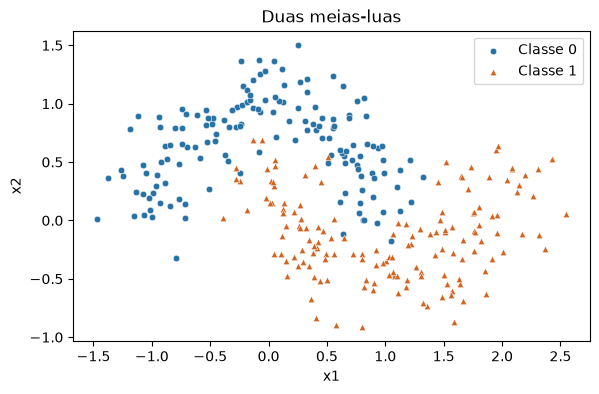

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_moons(n_samples=300, noise=0.20, random_state=42)


def plotar_pontos(ax, X, y):
    for classe, cor, marcador in [(0, "#2872A5", "o"), (1, "#D26422", "^")]:
        pontos = X[y == classe]
        ax.scatter(pontos[:, 0], pontos[:, 1], c=cor, marker=marcador,
                   s=22, edgecolors="white", linewidths=0.35, label=f"Classe {classe}")
    ax.set(xlabel="x1", ylabel="x2", aspect="equal")


fig, ax = plt.subplots(figsize=(6, 3.8), layout="constrained")
plotar_pontos(ax, X, y)
ax.set_title("Duas meias-luas")
ax.legend()
plt.show()

## 2. Separar os dados e treinar os modelos

Usamos 225 pontos para treinar e guardamos 75 para testar os dois modelos. O `StandardScaler` fica dentro do pipeline e aprende a escala dos dados usando só o treino. Depois, o mesmo pipeline prepara os pontos de teste e faz as previsões.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y,
)


def treinar_svm(kernel, C=1.0, gamma="scale"):
    modelo = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=C, gamma=gamma))
    return modelo.fit(X_train, y_train)


svm_linear = treinar_svm("linear")
svm_rbf = treinar_svm("rbf")

## 3. Comparar acurácia e erros

A acurácia mostra a proporção de acertos. Na matriz de confusão, as linhas são as classes reais e as colunas são as classes previstas, na ordem 0 e 1. Os acertos ficam na diagonal.

In [4]:
modelos = {"SVM linear": svm_linear, "SVM com RBF": svm_rbf}

for nome, modelo in modelos.items():
    previsoes = modelo.predict(X_test)
    acuracia_treino = modelo.score(X_train, y_train)
    acuracia_teste = accuracy_score(y_test, previsoes)
    print(f"{nome} | treino {acuracia_treino:.1%} | teste {acuracia_teste:.1%}")
    print(confusion_matrix(y_test, previsoes, labels=[0, 1]))
    print()

SVM linear | treino 88.4% | teste 85.3%
[[30  8]
 [ 3 34]]

SVM com RBF | treino 94.2% | teste 90.7%
[[32  6]
 [ 1 36]]



## 4. Ver as fronteiras lado a lado

Os pontos são do treino. O fundo mostra a classe que o modelo preveria em cada região. Na linha preta, a previsão troca de classe. O RBF consegue curvar essa linha e acompanhar melhor o formato das meias-luas.

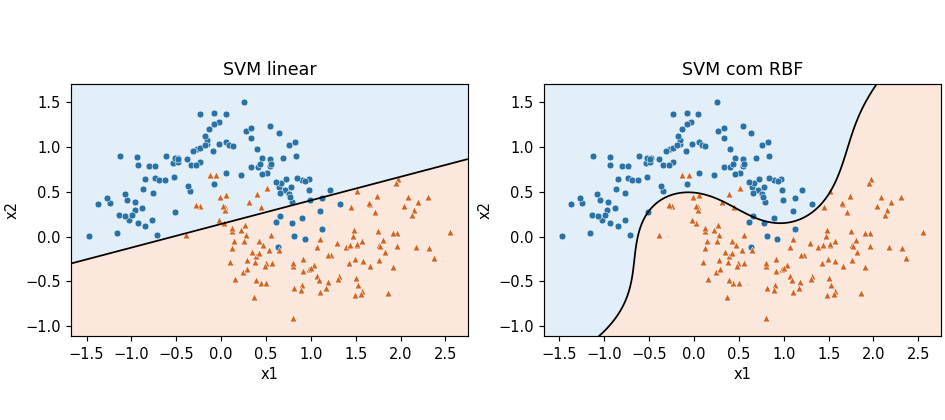

In [4]:
x_lim = (X[:, 0].min() - 0.2, X[:, 0].max() + 0.2)
y_lim = (X[:, 1].min() - 0.2, X[:, 1].max() + 0.2)
xx, yy = np.meshgrid(np.linspace(*x_lim, 250), np.linspace(*y_lim, 250))
grade = np.column_stack((xx.ravel(), yy.ravel()))


def plotar_fronteira(ax, modelo, titulo):
    # O pipeline recebe a grade nas coordenadas originais.
    regioes = modelo.predict(grade).reshape(xx.shape)
    decisoes = modelo.decision_function(grade).reshape(xx.shape)
    ax.contourf(xx, yy, regioes, levels=[-0.5, 0.5, 1.5], colors=["#E2EFF8", "#FBE7DB"])
    if decisoes.min() < 0 < decisoes.max():
        ax.contour(xx, yy, decisoes, levels=[0], colors="black", linewidths=1.2)
    plotar_pontos(ax, X_train, y_train)
    ax.set(title=titulo, xlim=x_lim, ylim=y_lim)


fig, eixos = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, (nome, modelo) in zip(eixos, modelos.items()):
    plotar_fronteira(ax, modelo, nome)
plt.show()

## 5. Variar C no RBF

Mantemos `gamma=1` para observar só o efeito de `C`. Um `C` maior penaliza mais os pontos que ficam dentro da margem ou do lado errado da fronteira.

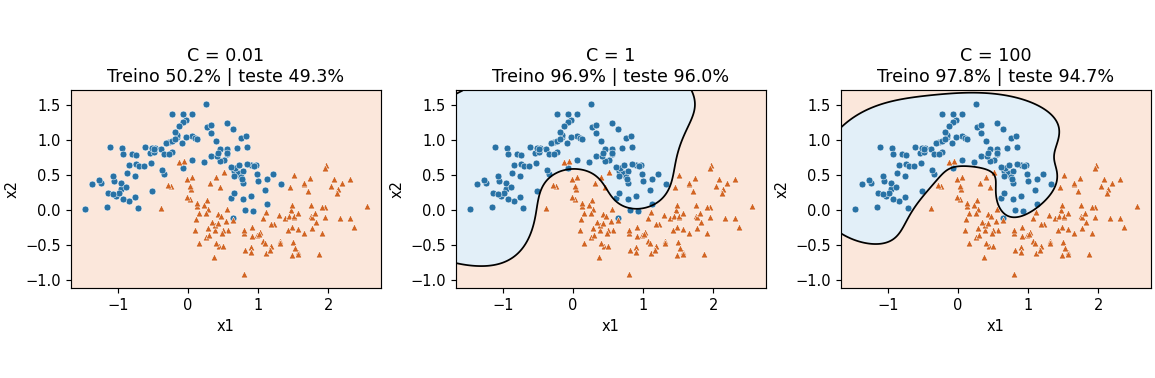

In [5]:
def comparar_configuracao(ax, modelo, nome):
    treino = modelo.score(X_train, y_train)
    teste = modelo.score(X_test, y_test)
    plotar_fronteira(ax, modelo, f"{nome}\nTreino {treino:.1%} | teste {teste:.1%}")


fig, eixos = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained")
for ax, C in zip(eixos, [0.01, 1, 100]):
    modelo = treinar_svm("rbf", C=C, gamma=1.0)
    comparar_configuracao(ax, modelo, f"C = {C}")
plt.show()

Com `C=0.01`, o modelo previu classe 1 para todos os pontos de teste e acertou 49,3%. De `C=1` para `C=100`, a acurácia subiu no treino, mas caiu de 96,0% para 94,7% no teste.

## 6. Variar gamma no RBF

Agora fixamos `C=1`. Quanto maior o `gamma`, menor o alcance da influência de cada vetor de suporte. A fronteira pode fazer curvas mais localizadas.

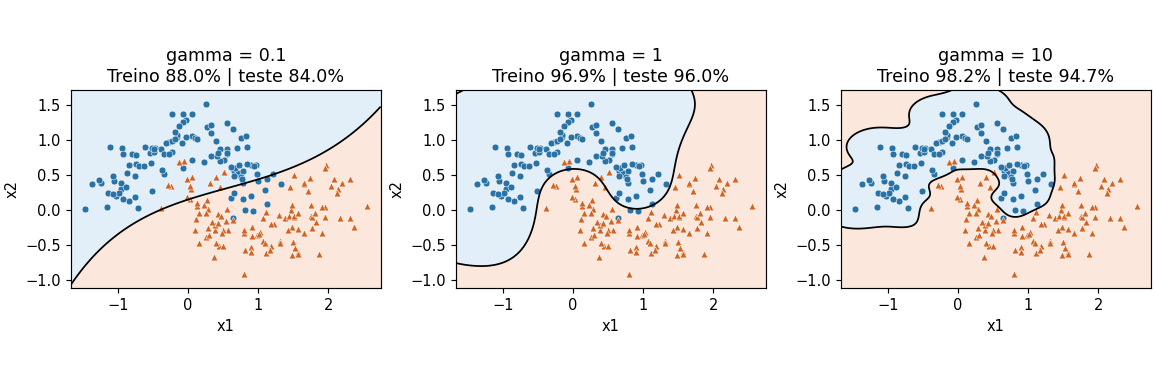

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained")
for ax, gamma in zip(eixos, [0.1, 1, 10]):
    modelo = treinar_svm("rbf", C=1.0, gamma=gamma)
    comparar_configuracao(ax, modelo, f"gamma = {gamma}")
plt.show()

Com `gamma=0.1`, a fronteira ficou mais suave e o modelo acertou 84,0% no teste. Com `gamma=1`, chegou a 96,0%. Ao subir para 10, a fronteira ficou mais recortada e a acurácia de teste caiu para 94,7%.

## Conclusão

Na comparação inicial, o SVM linear acertou 64 dos 75 pontos de teste. O RBF acertou 68 porque sua fronteira curva acompanhou melhor as meias-luas. Os experimentos mostram que apertar o ajuste no treino pode reduzir os acertos em pontos novos, como aconteceu ao passar de `C=1` para `C=100`.